# Gaussian Naïve Bayes on Iris Dataset

In this lab, we implement **Gaussian Naïve Bayes** for multiclass classification on the **built-in Iris dataset from scikit-learn**.

#### Mathematical Foundation:
1. **Bayes' Theorem**:
   $$P(y = c \mid X) = \frac{P(X \mid y = c) \cdot P(y = c)}{P(X)}$$
   $$\hat{y} = \arg\max_{c} P(y = c) \prod_{j=1}^d P(x_j \mid y = c)$$
2. **Gaussian Likelihood (for continuous real features)**:
   $$P(x_j \mid y = c) = \frac{1}{\sqrt{2\pi\sigma_{c,j}^2}} \exp\left( -\frac{(x_j - \mu_{c,j})^2}{2\sigma_{c,j}^2} \right)$$

### 1. Importing the necessary modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay

### 2. Loading the built-in Iris dataset directly from scikit-learn

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 3. Exploring feature distributions across classes
Naïve Bayes assumes features are normally (Gaussian) distributed within each class.

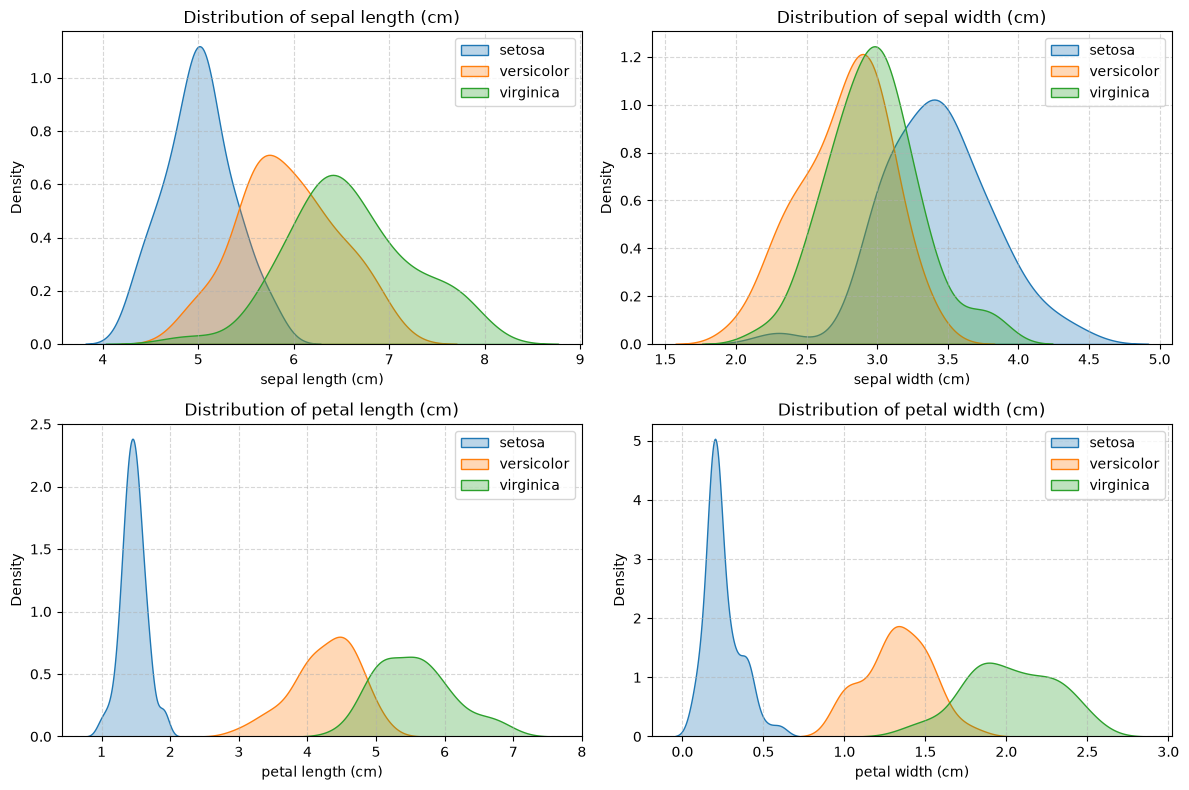

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
features = iris.feature_names

for idx, feature in enumerate(features):
    ax = axes[idx // 2, idx % 2]
    for species in iris.target_names:
        subset = df[df['species'] == species]
        sns.kdeplot(subset[feature], ax=ax, label=species, fill=True, alpha=0.3)
    ax.set_title(f"Distribution of {feature}")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 4. Slicing X (Features) and y (Target)

In [4]:
X = iris.data.values
y = iris.target.values
target_names = iris.target_names

print(f"X shape: {X.shape}, y shape: {y.shape}")
print("Classes:", target_names)

X shape: (150, 4), y shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


### 5. Splitting into Training and Test set

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)
print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")

Train samples: 120, Test samples: 30


### 6. Training the Gaussian Naïve Bayes model

In [6]:
classifier = GaussianNB()
classifier.fit(X_train, y_train)

# Inspect learned parameters: class priors P(y) and feature means mu
print("Class Priors P(y):", classifier.class_prior_)
print()
print("Learned Means for each class (mu):")
print(classifier.theta_)
print()
print("Learned Variances for each class (sigma^2):")
print(classifier.var_)

Class Priors P(y): [0.33333333 0.33333333 0.33333333]

Learned Means for each class (mu):
[[5.0025 3.4125 1.45   0.2475]
 [5.9025 2.75   4.2425 1.335 ]
 [6.6675 2.985  5.585  2.04  ]]

Learned Variances for each class (sigma^2):
[[0.13624375 0.15659375 0.0305     0.01149375]
 [0.24424375 0.1045     0.24544375 0.040275  ]
 [0.40519375 0.107775   0.338275   0.0669    ]]


### 7. Predicting the Test set results

In [7]:
y_pred = classifier.predict(X_test)
y_proba = classifier.predict_proba(X_test)

comparison_df = pd.DataFrame({
    "Actual": [target_names[i] for i in y_test],
    "Predicted": [target_names[i] for i in y_pred],
    "P(Setosa)": y_proba[:, 0].round(4),
    "P(Versicolor)": y_proba[:, 1].round(4),
    "P(Virginica)": y_proba[:, 2].round(4),
})
comparison_df.head(10)

,Actual,Predicted,P(Setosa),P(Versicolor),P(Virginica)
0,setosa,setosa,1.0,0.0000,0.0000
1,versicolor,versicolor,0.0,0.9995,0.0005
2,setosa,setosa,1.0,0.0000,0.0000
3,virginica,versicolor,0.0,0.6975,0.3025
4,setosa,setosa,1.0,0.0000,0.0000
5,versicolor,versicolor,0.0,0.9999,0.0001
6,virginica,virginica,0.0,0.0006,0.9994
7,setosa,setosa,1.0,0.0000,0.0000
8,setosa,setosa,1.0,0.0000,0.0000
9,versicolor,versicolor,0.0,1.0000,0.0000


### 8. Evaluating Model Performance (Accuracy, Confusion Matrix, Classification Report)

In [8]:
cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy Score: {accuracy * 100:.2f}%")
print()
print("Confusion Matrix:")
print(cm)
print()
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

Accuracy Score: 96.67%

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### 9. Syllabus Requirement: Cross-Validation
Evaluating the model across 5 distinct folds using `cross_val_score`.

In [9]:
cv_scores = cross_val_score(estimator=classifier, X=X, y=y, cv=5)

print("5-Fold Cross Validation Accuracy Scores:", cv_scores)
print(f"Mean CV Accuracy: {cv_scores.mean() * 100:.2f}%")
print(f"Standard Deviation: {cv_scores.std() * 100:.2f}%")

5-Fold Cross Validation Accuracy Scores: [0.93333333 0.96666667 0.93333333 0.93333333 1.        ]
Mean CV Accuracy: 95.33%
Standard Deviation: 2.67%


### 10. Visualizing Confusion Matrix & 2D Decision Boundary

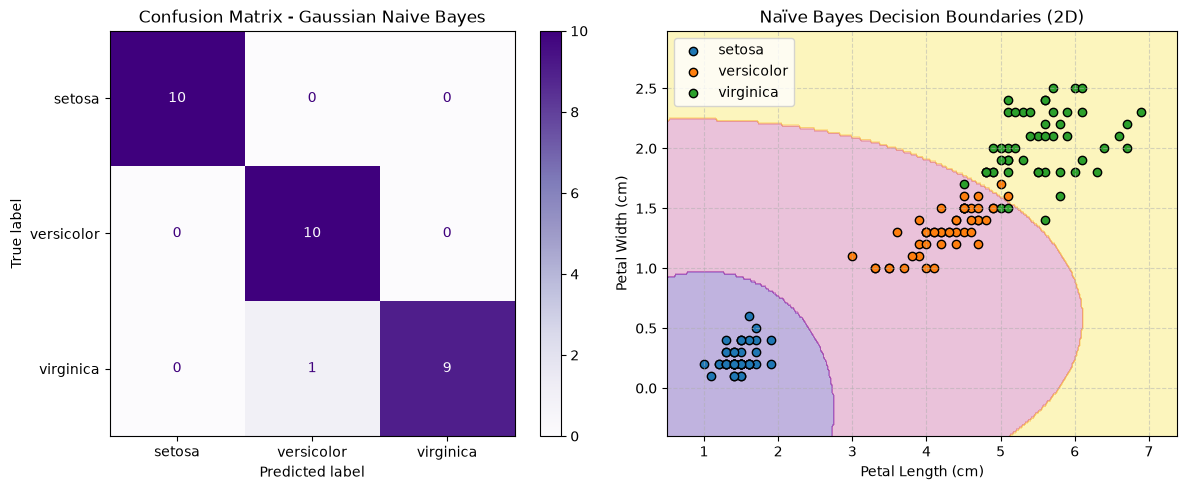

In [10]:
plt.figure(figsize=(12, 5))

# Plot 1: Confusion Matrix
plt.subplot(1, 2, 1)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap=plt.cm.Purples, ax=plt.gca())
plt.title("Confusion Matrix - Gaussian Naive Bayes")
plt.grid(False)

# Plot 2: 2D Decision Boundary on Petal Length vs Petal Width
plt.subplot(1, 2, 2)
X_2d = df[['petal length (cm)', 'petal width (cm)']].values
nb_2d = GaussianNB().fit(X_2d, y)

x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = nb_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.plasma)
for class_idx, species in enumerate(target_names):
    plt.scatter(
        X_2d[y == class_idx, 0],
        X_2d[y == class_idx, 1],
        label=species,
        edgecolor="k"
    )
plt.title("Naïve Bayes Decision Boundaries (2D)")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()